# MNIST Digit Classification with a CNN (Colab-ready)

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

Fixes vs. the original notebook:
- Separate validation split (the test set is used only once, at the end — no leakage)
- Augmentation lives inside the model, so it runs on the GPU and switches off automatically at inference
- Correct rotation range (±10°, not ±36°)
- EarlyStopping and ModelCheckpoint watch the same metric, so the saved model is the best model
- `keras.Input` layer (no `input_shape` warning)
- No emoji in plots (no missing-glyph warnings)
- Robust upload preprocessing: transparent PNGs, cropping, MNIST-style centering
- Fixed random seed for reproducibility

In [1]:
# ── 1. Setup ─────────────────────────────────────────────────────────
import io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow : {tf.__version__}")
print(f"Keras      : {keras.__version__}")
print(f"GPU        : {gpus if gpus else 'NONE - enable it via Runtime > Change runtime type'}")

TensorFlow : 2.21.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : (54000, 28, 28)  Val : (6000, 28, 28)  Test : (10000, 28, 28)
Pixel range: [0, 255]   Classes: [0 1 2 3 4 5 6 7 8 9]


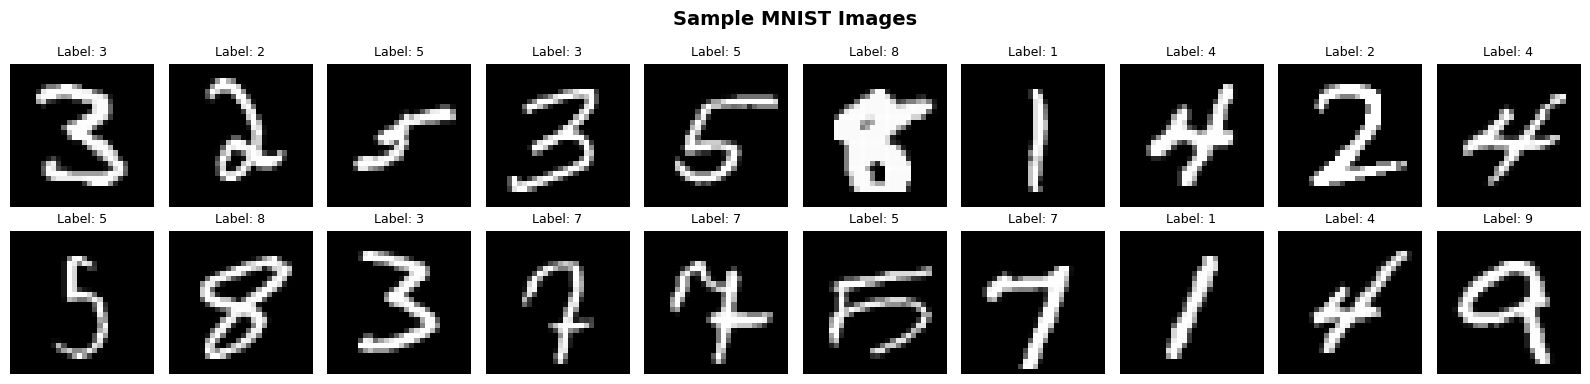

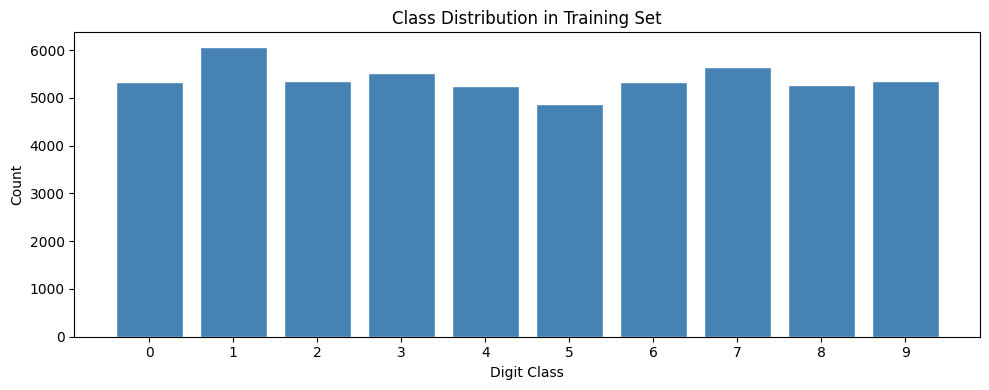

In [2]:
# ── 2. Load data and create a validation split ──────────────────────
(X_full, y_full), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.1, random_state=SEED, stratify=y_full
)

print(f"Train : {X_train.shape}  Val : {X_val.shape}  Test : {X_test.shape}")
print(f"Pixel range: [{X_full.min()}, {X_full.max()}]   Classes: {np.unique(y_full)}")

# Sample images
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
fig.suptitle("Sample MNIST Images", fontsize=14, fontweight="bold")
for ax, idx in zip(axes.flat, rng.choice(len(X_train), 20, replace=False)):
    ax.imshow(X_train[idx], cmap="gray")
    ax.set_title(f"Label: {y_train[idx]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

# Class distribution
plt.figure(figsize=(10, 4))
plt.bar(range(10), np.bincount(y_train), color="steelblue", edgecolor="white")
plt.xticks(range(10)); plt.xlabel("Digit Class"); plt.ylabel("Count")
plt.title("Class Distribution in Training Set")
plt.tight_layout(); plt.show()

In [3]:
# ── 3. Preprocess ───────────────────────────────────────────────────
NUM_CLASSES = 10

def prep(x):
    return (x.astype("float32") / 255.0)[..., np.newaxis]   # (N, 28, 28, 1)

X_train, X_val, X_test = prep(X_train), prep(X_val), prep(X_test)
y_train_ohe = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_ohe   = keras.utils.to_categorical(y_val,   NUM_CLASSES)
y_test_ohe  = keras.utils.to_categorical(y_test,  NUM_CLASSES)

print(f"X_train {X_train.shape}  range [{X_train.min():.2f}, {X_train.max():.2f}]")

X_train (54000, 28, 28, 1)  range [0.00, 1.00]


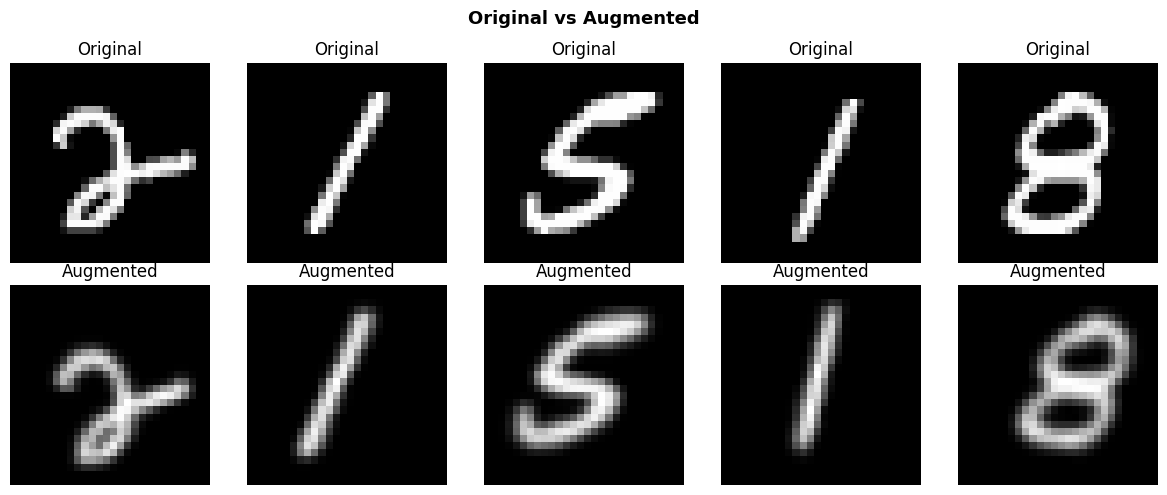

In [4]:
# ── 4. Data augmentation (inside the model → GPU, inactive at inference)
data_augmentation = keras.Sequential([
    layers.RandomRotation(factor=10 / 360),    # ±10 degrees
    layers.RandomZoom(height_factor=0.1),      # ±10 % zoom
    layers.RandomTranslation(0.1, 0.1),        # ±10 % shift
], name="augmentation")

sample = X_train[:5]
aug = data_augmentation(sample, training=True).numpy()
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Original vs Augmented", fontsize=13, fontweight="bold")
for i in range(5):
    axes[0, i].imshow(sample[i, :, :, 0], cmap="gray"); axes[0, i].set_title("Original");  axes[0, i].axis("off")
    axes[1, i].imshow(aug[i, :, :, 0],    cmap="gray"); axes[1, i].set_title("Augmented"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [5]:
# ── 5. Build the model ──────────────────────────────────────────────
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(0.25)(x)

def build_model(input_shape=(28, 28, 1), num_classes=10):
    inputs = keras.Input(shape=input_shape)
    x = data_augmentation(inputs)          # only active when training=True
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = layers.Flatten()(x)
    x = layers.Dense(256)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="MNIST_CNN")

model = build_model()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 872,426 (3.33 MB)

 Trainable params: 871,530 (3.32 MB)

 Non-trainable params: 896 (3.50 KB)

In [6]:
# ── 6. Input pipelines ──────────────────────────────────────────────
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train_ohe))
            .shuffle(len(X_train), seed=SEED)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val_ohe))
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

In [7]:
# ── 7. Callbacks (all monitor val_loss → saved model == restored model)
callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    ModelCheckpoint("best_mnist_model.keras", monitor="val_loss", save_best_only=True, verbose=1),
]

In [8]:
# ── 8. Train ────────────────────────────────────────────────────────
EPOCHS = 30
history = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds,
                    callbacks=callbacks, verbose=1)
print("\nTraining complete.")

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8003 - loss: 0.6285
Epoch 1: val_loss improved from None to 2.08272, saving model to best_mnist_model.keras

Epoch 1: finished saving model to best_mnist_model.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.9052 - loss: 0.3073 - val_accuracy: 0.3235 - val_loss: 2.0827 - learning_rate: 0.0010
Epoch 2/30
420/422 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9656 - loss: 0.1143
Epoch 2: val_loss improved from 2.08272 to 0.12272, saving model to best_mnist_model.keras

Epoch 2: finished saving model to best_mnist_model.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9699 - loss: 0.1006 - val_accuracy: 0.9643 - val_loss: 0.1227 - learning_rate: 0.0010
Epoch 3/30
420/422 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9759 - loss: 0.0781
Epoch 3: val_loss improved from 0.12272 to 0.04708, saving model to best_mnist_model.keras

Epoch 3: finished saving model to best_mnist_model.keras
422/422 ━

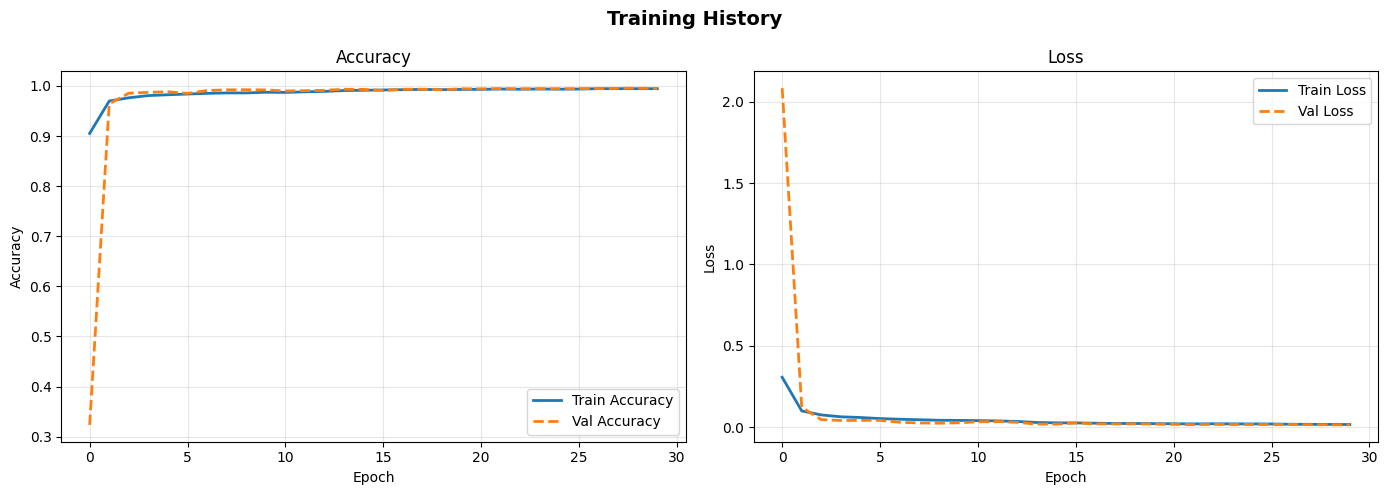

In [9]:
# ── 9. Training curves ──────────────────────────────────────────────
def plot_history(history):
    h = history.history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Training History", fontsize=14, fontweight="bold")
    for ax, key, title in [(ax1, "accuracy", "Accuracy"), (ax2, "loss", "Loss")]:
        ax.plot(h[key], label=f"Train {title}", lw=2)
        ax.plot(h[f"val_{key}"], label=f"Val {title}", lw=2, linestyle="--")
        ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(title)
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_history(history)

In [10]:
# ── 10. Final evaluation on the untouched test set (run once) ───────
test_loss, test_acc = model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc * 100:.2f}%")

Test Loss     : 0.0109
Test Accuracy : 99.60%


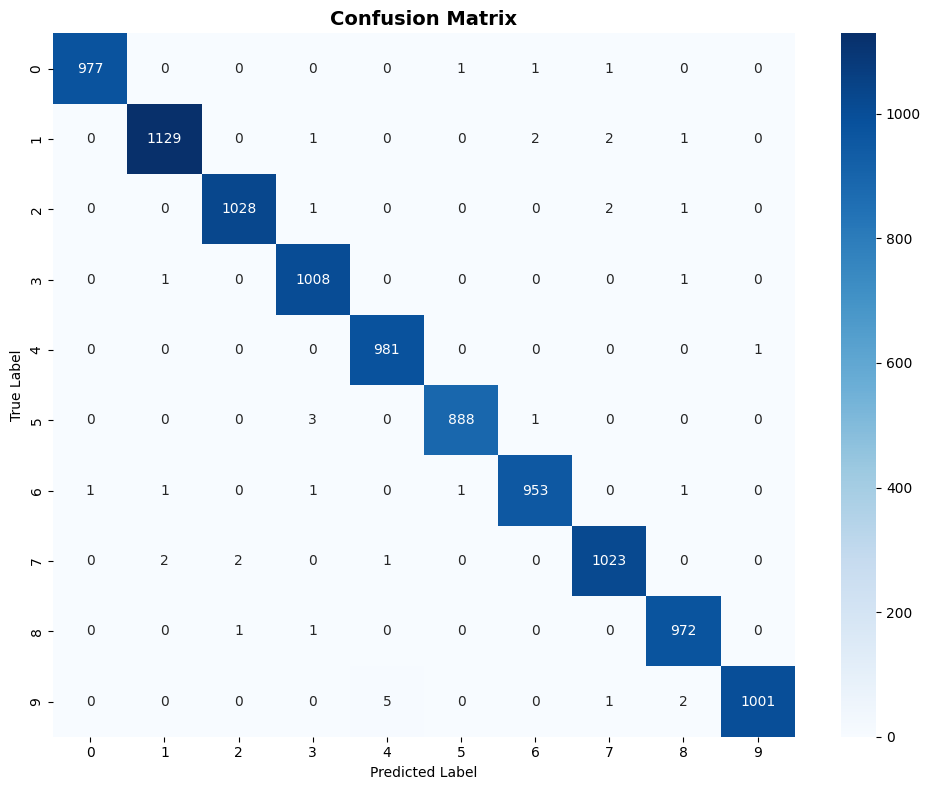

              precision    recall  f1-score   support

           0     0.9990    0.9969    0.9980       980
           1     0.9965    0.9947    0.9956      1135
           2     0.9971    0.9961    0.9966      1032
           3     0.9931    0.9980    0.9956      1010
           4     0.9939    0.9990    0.9964       982
           5     0.9978    0.9955    0.9966       892
           6     0.9958    0.9948    0.9953       958
           7     0.9942    0.9951    0.9947      1028
           8     0.9939    0.9979    0.9959       974
           9     0.9990    0.9921    0.9955      1009

    accuracy                         0.9960     10000
   macro avg     0.9960    0.9960    0.9960     10000
weighted avg     0.9960    0.9960    0.9960     10000



In [11]:
# ── 11. Confusion matrix and classification report ──────────────────
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.title("Confusion Matrix", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label"); plt.ylabel("True Label")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)], digits=4))

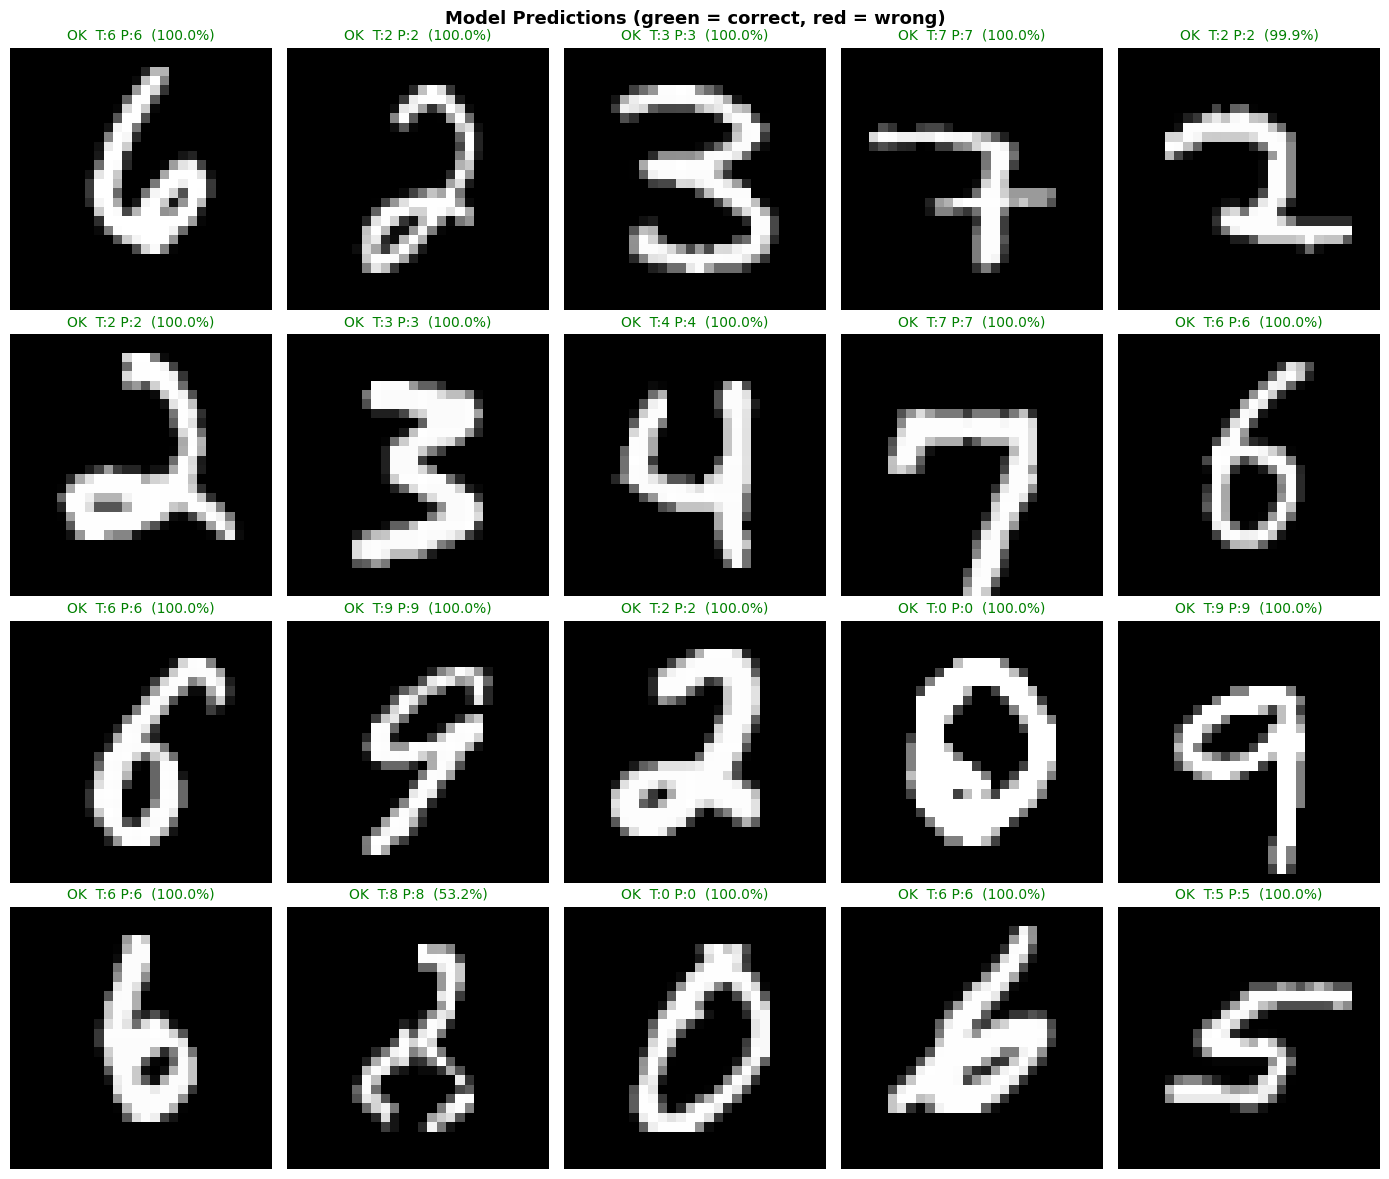

In [12]:
# ── 12. Random test predictions ─────────────────────────────────────
def visualise_predictions(X, y_true, y_pred, probs, n=20):
    idxs = np.random.choice(len(X), n, replace=False)
    fig, axes = plt.subplots(4, 5, figsize=(14, 12))
    fig.suptitle("Model Predictions (green = correct, red = wrong)", fontsize=13, fontweight="bold")
    for ax, i in zip(axes.flat, idxs):
        ok = y_true[i] == y_pred[i]
        ax.imshow(X[i, :, :, 0], cmap="gray")
        ax.set_title(f"{'OK' if ok else 'X'}  T:{y_true[i]} P:{y_pred[i]}  ({probs[i].max()*100:.1f}%)",
                     color="green" if ok else "red", fontsize=10)
        ax.axis("off")
    plt.tight_layout(); plt.show()

visualise_predictions(X_test, y_test, y_pred, y_pred_probs)

Misclassified: 40 / 10000  (0.40%)


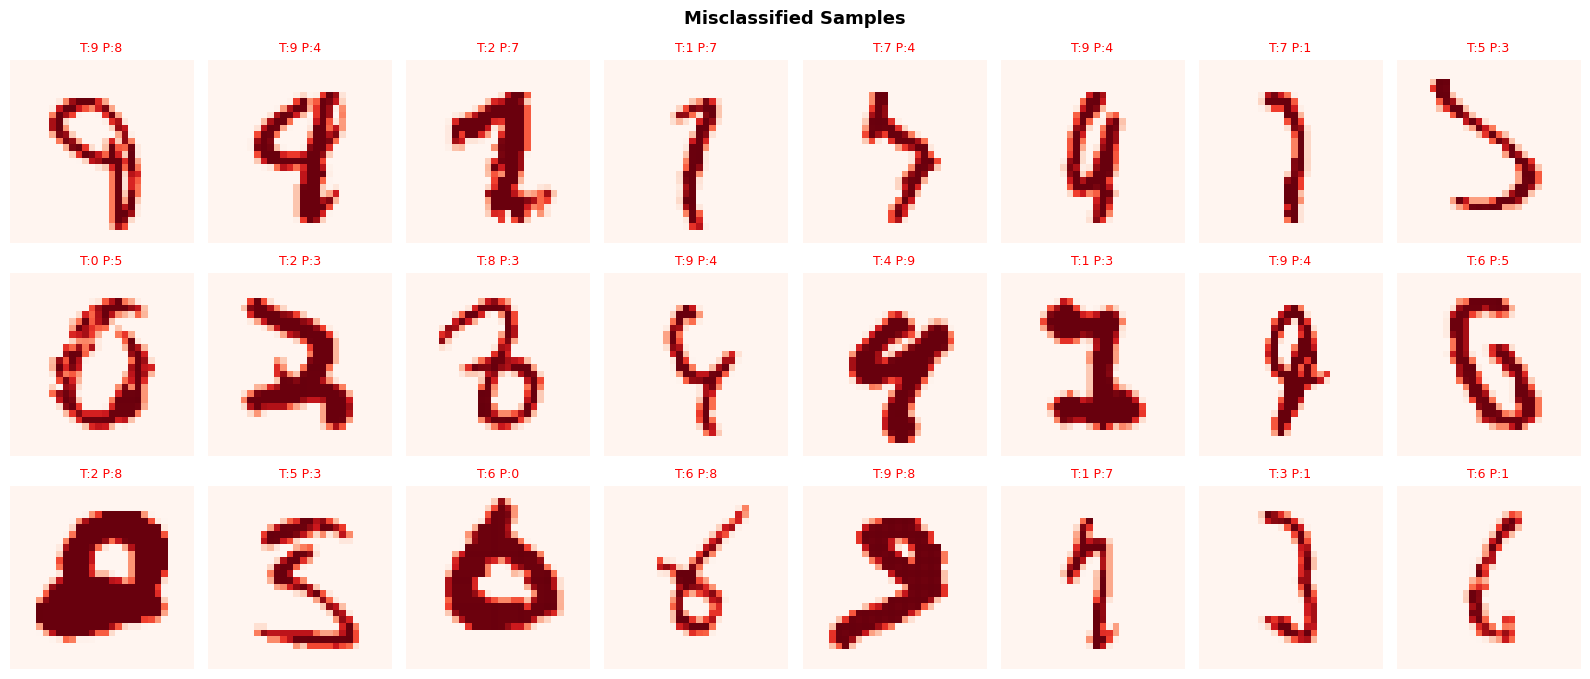

In [13]:
# ── 13. Misclassified samples ───────────────────────────────────────
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong_idx)} / {len(y_test)}  ({len(wrong_idx)/len(y_test)*100:.2f}%)")

if len(wrong_idx):
    fig, axes = plt.subplots(3, 8, figsize=(16, 7))
    fig.suptitle("Misclassified Samples", fontsize=13, fontweight="bold")
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, wrong_idx[:24]):
        ax.imshow(X_test[i, :, :, 0], cmap="Reds")
        ax.set_title(f"T:{y_test[i]} P:{y_pred[i]}", fontsize=9, color="red")
    plt.tight_layout(); plt.show()

In [14]:
# ── 14. Save, reload and verify ─────────────────────────────────────
model.save("mnist_cnn_final.keras")
loaded_model = keras.models.load_model("mnist_cnn_final.keras")
_, loaded_acc = loaded_model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Saved → mnist_cnn_final.keras   (reloaded accuracy: {loaded_acc*100:.2f}%)")

print(f"Total params     : {model.count_params():,}")
print(f"Trainable params : {sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}")

# Optional: download the model to your computer
# from google.colab import files; files.download("mnist_cnn_final.keras")

Saved → mnist_cnn_final.keras   (reloaded accuracy: 99.60%)
Total params     : 872,426
Trainable params : 871,530


In [15]:
# ── 15. Robust preprocessing for your own images ────────────────────
def preprocess_image(img: Image.Image) -> np.ndarray:
    """Any PIL image → (1, 28, 28, 1) float32 in MNIST style."""
    # 1. Flatten transparency onto white (fixes all-black transparent PNGs)
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(bg, img)
    arr = np.array(img.convert("L"), dtype="float32") / 255.0

    # 2. MNIST is white digit on black background → invert light backgrounds
    if arr.mean() > 0.5:
        arr = 1.0 - arr

    # 3. Remove faint background noise
    arr[arr < 0.2] = 0.0

    # 4. Crop tightly to the digit
    ys, xs = np.nonzero(arr)
    if len(xs) == 0:
        return np.zeros((1, 28, 28, 1), "float32")
    arr = arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

    # 5. Pad to square, resize to fit a 20×20 box (as in MNIST)
    h, w = arr.shape
    s = max(h, w)
    square = np.zeros((s, s), "float32")
    square[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = arr
    small = Image.fromarray((square * 255).astype("uint8")).resize((20, 20), Image.LANCZOS)
    small = np.array(small, dtype="float32") / 255.0

    # 6. Place in 28×28 canvas and centre by centre of mass (as in MNIST)
    canvas = np.zeros((28, 28), "float32")
    canvas[4:24, 4:24] = small
    cy, cx = ndimage.center_of_mass(canvas)
    canvas = ndimage.shift(canvas, (14 - cy, 14 - cx), mode="constant")
    canvas = np.clip(canvas, 0.0, 1.0)

    return canvas[np.newaxis, ..., np.newaxis]

Click 'Choose Files' and upload one or more digit images ...


Saving Screenshot 2026-11-06 162553.png to Screenshot 2026-11-06 162553.png


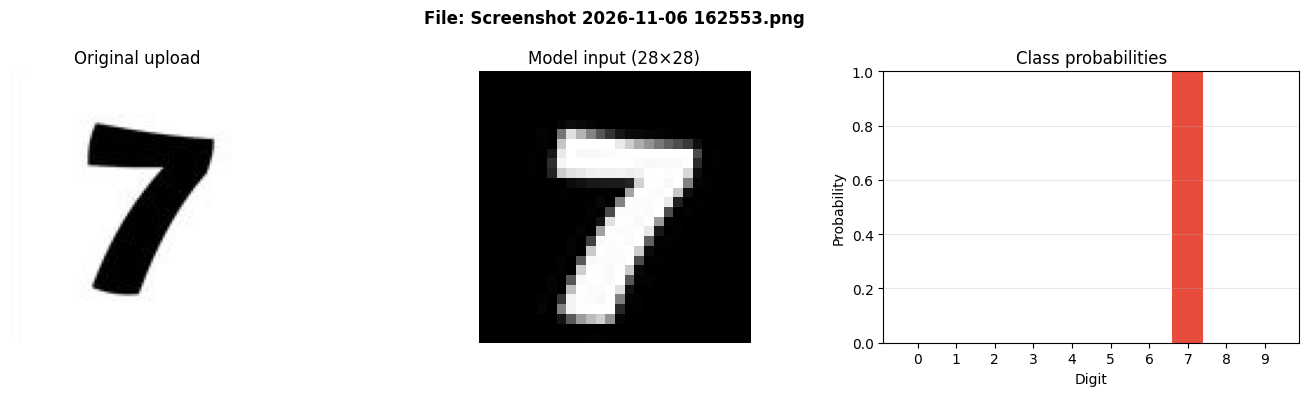

Predicted digit : 7   (confidence 99.98%)
  0:                                  0.00%
  1:                                  0.00%
  2:                                  0.00%
  3:                                  0.00%
  4:                                  0.00%
  5:                                  0.00%
  6:                                  0.00%
  7: ██████████████████████████████  99.98%  <- predicted
  8:                                  0.00%
  9:                                  0.00%


In [16]:
# ── 16. Upload images and predict ───────────────────────────────────
from google.colab import files

def upload_and_predict(model):
    print("Click 'Choose Files' and upload one or more digit images ...")
    uploaded = files.upload()
    if not uploaded:
        print("No file uploaded."); return

    for filename, raw in uploaded.items():
        try:
            pil_img = Image.open(io.BytesIO(raw))
        except Exception as e:
            print(f"{filename}: could not open image ({e})"); continue

        x = preprocess_image(pil_img)
        probs = model.predict(x, verbose=0)[0]
        pred = int(np.argmax(probs))

        fig, axes = plt.subplots(1, 3, figsize=(14, 4))
        fig.suptitle(f"File: {filename}", fontsize=12, fontweight="bold")
        axes[0].imshow(np.array(pil_img.convert("L")), cmap="gray"); axes[0].set_title("Original upload"); axes[0].axis("off")
        axes[1].imshow(x[0, :, :, 0], cmap="gray"); axes[1].set_title("Model input (28×28)"); axes[1].axis("off")
        colors = ["#4a90d9"] * 10; colors[pred] = "#e74c3c"
        axes[2].bar(range(10), probs, color=colors)
        axes[2].set_xticks(range(10)); axes[2].set_ylim(0, 1)
        axes[2].set_xlabel("Digit"); axes[2].set_ylabel("Probability")
        axes[2].set_title("Class probabilities"); axes[2].grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.show()

        print(f"Predicted digit : {pred}   (confidence {probs[pred]*100:.2f}%)")
        for d, p in enumerate(probs):
            print(f"  {d}: {'█' * round(p * 30):<30} {p*100:6.2f}%{'  <- predicted' if d == pred else ''}")

upload_and_predict(model)

Re-run the cell below any time to test more images.

Click 'Choose Files' and upload one or more digit images ...


Saving Screenshot 2026-11-06 163828.png to Screenshot 2026-11-06 163828.png


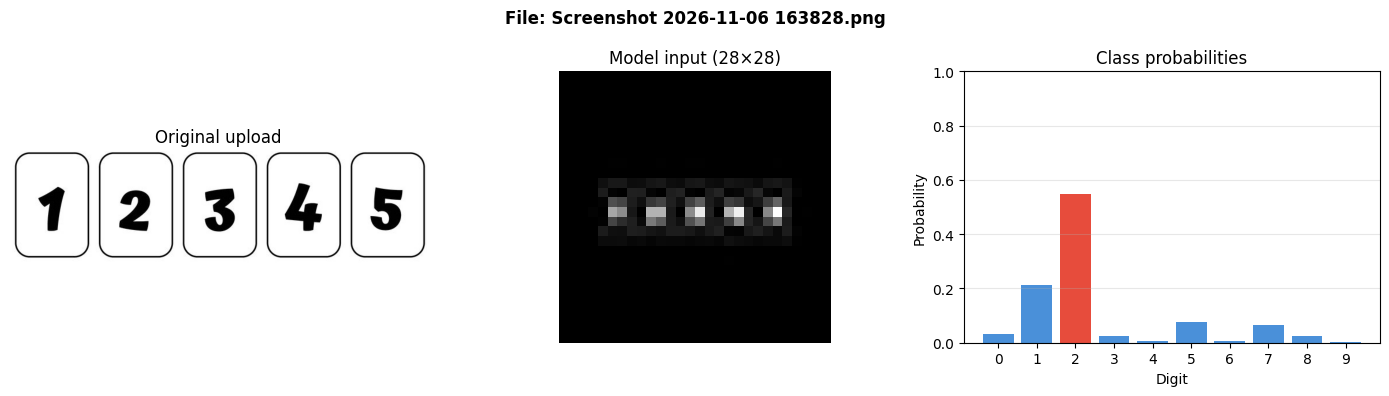

Predicted digit : 2   (confidence 54.70%)
  0: █                                3.07%
  1: ██████                          21.43%
  2: ████████████████                54.70%  <- predicted
  3: █                                2.55%
  4:                                  0.73%
  5: ██                               7.67%
  6:                                  0.59%
  7: ██                               6.43%
  8: █                                2.40%
  9:                                  0.44%


In [17]:
upload_and_predict(model)